# EDA: KanjiVG dataset (`data/kanji`)

Population: every SVG file in `data/kanji`. One file = one character; filename = Unicode
codepoint in hex. Questions:

1. What characters are in the set, and how are strokes distributed?
2. How are components (`kvg:element` groups) nested, and how many distinct ones are there?
3. How concentrated is component frequency (how many kanji does each component appear in)?
4. Which structural annotations (`position`, `radical`, `part`, `variant`) are present and how often?
5. Which stroke types (`kvg:type`) occur?

In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display

KANJIVG_DIR = Path("data/kanji")
KVG = "{http://kanjivg.tagaini.net}"
SVG_GROUP_TAG = "{http://www.w3.org/2000/svg}g"
SVG_PATH_TAG = "{http://www.w3.org/2000/svg}path"

In [2]:
SERIES_BLUE = "#2a78d6"
TEXT_SECONDARY = "#52514e"
GRID_GRAY = "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID_GRAY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID_GRAY,
    "axes.axisbelow": True,
    "font.family": ["Noto Sans CJK JP", "DejaVu Sans"],
})

## 1. Files and character classes

In [3]:
svg_files = sorted(KANJIVG_DIR.glob("*.svg"))
print("files:", len(svg_files))
print("non-standard filenames:", sum(len(f.stem) != 5 for f in svg_files))

files: 6703
non-standard filenames: 0


In [4]:
def character_class(character):
    name = unicodedata.name(character, "?")
    first_word = name.split()[0]
    if first_word == "CJK":
        return "CJK ideograph"
    if first_word in {"HIRAGANA", "KATAKANA", "KATAKANA-HIRAGANA"}:
        return "kana"
    return "other (latin, digits, punctuation)"

⚠️ All files stay in the population, including kana and ASCII glyphs. Kanji-only sections
below filter to `CJK ideograph`; counts in sections 1 and 5 include everything.

In [5]:
def parse_character_file(filepath):
    root = ET.parse(filepath).getroot()
    stroke_paths_group = next(
        g for g in root.iter(SVG_GROUP_TAG) if g.get("id", "").startswith("kvg:StrokePaths")
    )
    top_group = next(g for g in stroke_paths_group if g.tag == SVG_GROUP_TAG)
    return top_group


def walk_groups(group, depth, rows, character):
    element = group.get(KVG + "element")
    stroke_count = sum(1 for _ in group.iter(SVG_PATH_TAG))
    child_groups = [child for child in group if child.tag == SVG_GROUP_TAG]
    rows.append({
        "character": character,
        "depth": depth,
        "element": element,
        "position": group.get(KVG + "position"),
        "radical": group.get(KVG + "radical"),
        "variant": group.get(KVG + "variant"),
        "original": group.get(KVG + "original"),
        "part": group.get(KVG + "part"),
        "partial": group.get(KVG + "partial"),
        "phon": group.get(KVG + "phon"),
        "stroke_count": stroke_count,
        "child_group_count": len(child_groups),
    })
    for child in child_groups:
        walk_groups(child, depth + 1, rows, character)

In [6]:
group_rows = []
stroke_rows = []
for filepath in svg_files:
    character = chr(int(filepath.stem, 16))
    top_group = parse_character_file(filepath)
    walk_groups(top_group, 0, group_rows, character)
    for stroke_index, path in enumerate(top_group.iter(SVG_PATH_TAG), start=1):
        stroke_rows.append({
            "character": character,
            "stroke_index": stroke_index,
            "stroke_type": path.get(KVG + "type"),
        })

group_table = pd.DataFrame(group_rows)
stroke_table = pd.DataFrame(stroke_rows)
print("groups:", len(group_table), " strokes:", len(stroke_table))

groups: 48968  strokes: 79921


In [7]:
root_groups = group_table[group_table["depth"] == 0].set_index("character")
component_groups = group_table[group_table["depth"] > 0]
named_component_count = component_groups.dropna(subset=["element"]).groupby("character").size()

character_table = pd.DataFrame({
    "character": root_groups.index,
    "codepoint": [ord(c) for c in root_groups.index],
    "character_class": [character_class(c) for c in root_groups.index],
    "root_element": root_groups["element"].values,
    "stroke_count": root_groups["stroke_count"].values,
    "component_count": named_component_count.reindex(root_groups.index, fill_value=0).values,
    "max_depth": group_table.groupby("character")["depth"].max().reindex(root_groups.index).values,
}).reset_index(drop=True)
print("characters:", len(character_table))
character_table.head()

characters: 6703


,character,codepoint,character_class,root_element,stroke_count,component_count,max_depth
0,!,33,"other (latin, digits, punctuation)",!,2,0,0
1,",",44,"other (latin, digits, punctuation)",",",1,0,0
2,.,46,"other (latin, digits, punctuation)",.,1,0,0
3,0,48,"other (latin, digits, punctuation)",0,1,0,0
4,1,49,"other (latin, digits, punctuation)",1,1,0,0


In [8]:
class_counts = character_table["character_class"].value_counts()
class_share = (class_counts / len(character_table)).round(4)
pd.DataFrame({"n": class_counts, "share": class_share})

,n,share
character_class,,
CJK ideograph,6446,0.9617
kana,184,0.0275
"other (latin, digits, punctuation)",73,0.0109


In [9]:
mismatched_root = character_table[character_table["root_element"] != character_table["character"]]
print("root element != filename character:", len(mismatched_root), "of", len(character_table))
mismatched_root

root element != filename character: 1 of 6703


,character,codepoint,character_class,root_element,stroke_count,component_count,max_depth
2848,橅,27205,CJK ideograph,機,16,5,3


## 2. Stroke counts

In [10]:
kanji_table = character_table[character_table["character_class"] == "CJK ideograph"]
print("kanji rows:", len(kanji_table), "of", len(character_table))
kanji_table["stroke_count"].describe().round(2)

kanji rows: 6446 of 6703


count    6446.00
mean       12.29
std         4.60
min         1.00
25%         9.00
50%        12.00
75%        15.00
max        30.00
Name: stroke_count, dtype: float64

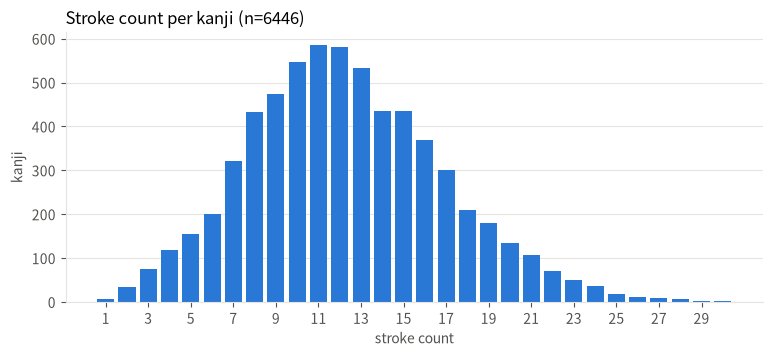

In [11]:
stroke_count_distribution = kanji_table["stroke_count"].value_counts().sort_index()

figure, axis = plt.subplots(figsize=(9, 3.5))
axis.bar(stroke_count_distribution.index, stroke_count_distribution.values,
         color=SERIES_BLUE, width=0.8)
axis.set_xlabel("stroke count")
axis.set_ylabel("kanji")
axis.set_title(f"Stroke count per kanji (n={len(kanji_table)})", loc="left")
axis.set_xticks(range(1, stroke_count_distribution.index.max() + 1, 2))
plt.show()

In [12]:
character_table.groupby("character_class")["stroke_count"].agg(["count", "min", "median", "max"])

,count,min,median,max
character_class,,,,
CJK ideograph,6446,1,12.0,30
kana,184,1,3.0,6
"other (latin, digits, punctuation)",73,1,2.0,4


## 3. Component structure

⚠️ A "component" is any `<g kvg:element=...>` below the root group, at every nesting level
(顔 → 彦 and also 彦 → 立, 厂, 彡). Groups without `kvg:element` are structural and counted
separately. This inflates per-kanji counts relative to direct children only.

In [13]:
component_groups_without_element = component_groups["element"].isna().sum()
print("component groups:", len(component_groups))
print("  with kvg:element:", component_groups["element"].notna().sum())
print("  without kvg:element:", component_groups_without_element)

component groups: 42265
  with kvg:element: 37301
  without kvg:element: 4964


In [14]:
named_components = component_groups[component_groups["element"].notna()]
print("named component groups:", len(named_components), "of", len(component_groups))
print("distinct element labels:", named_components["element"].nunique())

named component groups: 37301 of 42265
distinct element labels: 1464


In [15]:
kanji_components = named_components[named_components["character"].isin(kanji_table["character"])]
print("named component groups in kanji:", len(kanji_components), "of", len(named_components))
kanji_table["component_count"].describe().round(2)

named component groups in kanji: 37301 of 37301


count    6446.00
mean        5.79
std         2.92
min         0.00
25%         4.00
50%         5.00
75%         7.00
max        20.00
Name: component_count, dtype: float64

In [16]:
kanji_without_components = kanji_table[kanji_table["component_count"] == 0]
print("kanji with zero named components:", len(kanji_without_components), "of", len(kanji_table))
kanji_without_components.head(10)

kanji with zero named components: 131 of 6446


,character,codepoint,character_class,root_element,stroke_count,component_count,max_depth
68,⺉,11913,CJK ideograph,⺉,2,0,0
69,⺌,11916,CJK ideograph,⺌,3,0,0
70,⺍,11917,CJK ideograph,⺍,3,0,0
71,⺕,11925,CJK ideograph,⺕,3,0,0
72,⺗,11927,CJK ideograph,⺗,4,0,0
73,⺡,11937,CJK ideograph,⺡,3,0,0
74,⺢,11938,CJK ideograph,⺢,5,0,0
75,⺤,11940,CJK ideograph,⺤,4,0,0
76,⺦,11942,CJK ideograph,⺦,3,0,0
77,⺨,11944,CJK ideograph,⺨,3,0,0


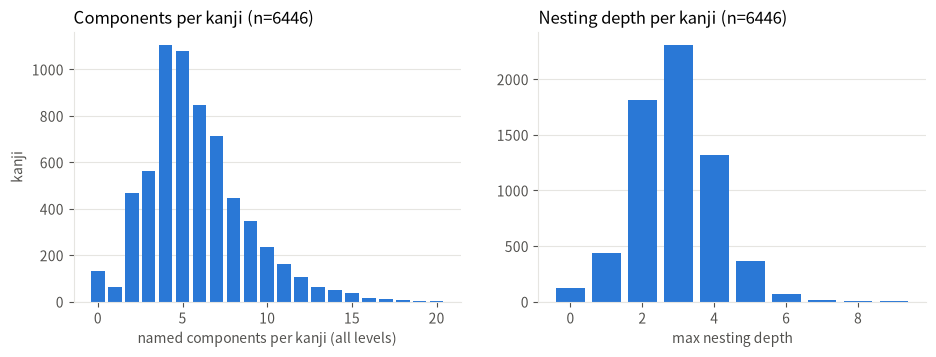

In [17]:
depth_distribution = kanji_table["max_depth"].value_counts().sort_index()
component_count_distribution = kanji_table["component_count"].value_counts().sort_index()

figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
left_axis.bar(component_count_distribution.index, component_count_distribution.values,
              color=SERIES_BLUE, width=0.8)
left_axis.set_xlabel("named components per kanji (all levels)")
left_axis.set_ylabel("kanji")
left_axis.set_title(f"Components per kanji (n={len(kanji_table)})", loc="left")

right_axis.bar(depth_distribution.index, depth_distribution.values, color=SERIES_BLUE, width=0.8)
right_axis.set_xlabel("max nesting depth")
right_axis.set_title(f"Nesting depth per kanji (n={len(kanji_table)})", loc="left")
plt.show()

Spearman r: 0.64


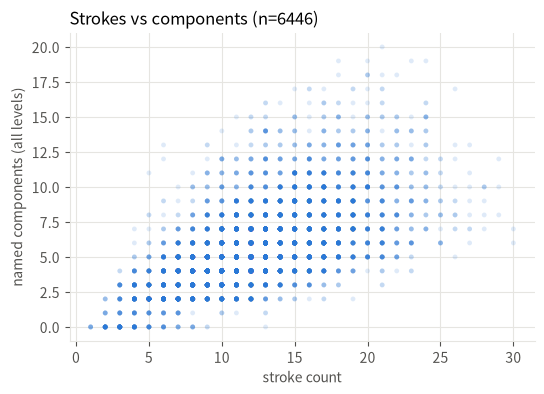

In [18]:
figure, axis = plt.subplots(figsize=(6, 4))
axis.scatter(kanji_table["stroke_count"], kanji_table["component_count"],
             s=12, alpha=0.15, color=SERIES_BLUE, edgecolors="none")
axis.set_xlabel("stroke count")
axis.set_ylabel("named components (all levels)")
axis.set_title(f"Strokes vs components (n={len(kanji_table)})", loc="left")
axis.grid(True, axis="both")
stroke_rank = kanji_table["stroke_count"].rank()
component_rank = kanji_table["component_count"].rank()
spearman_r = stroke_rank.corr(component_rank)
print("Spearman r:", round(spearman_r, 3))
plt.show()

## 4. Component frequency

⚠️ Components split with `kvg:part` (e.g. 丗 → 廿 part 1..4) are one occurrence: only
`part` missing or `"1"` is kept. Frequency is measured as *document frequency*: the number of
kanji whose tree contains the element at any level, each kanji counted once per element.

In [19]:
first_parts = kanji_components[kanji_components["part"].isna() | (kanji_components["part"] == "1")]
print("component groups before part-dedup:", len(kanji_components), " after:", len(first_parts))

component groups before part-dedup: 37301  after: 35514


In [20]:
component_document_frequency = (
    first_parts.groupby("element")["character"].nunique().sort_values(ascending=False)
)
component_occurrences = first_parts.groupby("element").size().sort_values(ascending=False)
print("distinct elements in kanji:", len(component_document_frequency))
component_document_frequency.head(20)

distinct elements in kanji: 1464


element
丿    1607
口    1601
一     881
日     770
木     727
十     634
八     585
亠     568
亻     488
人     435
丶     432
丨     422
土     417
艹     404
冖     396
目     395
大     365
氵     365
月     364
田     325
Name: character, dtype: int64

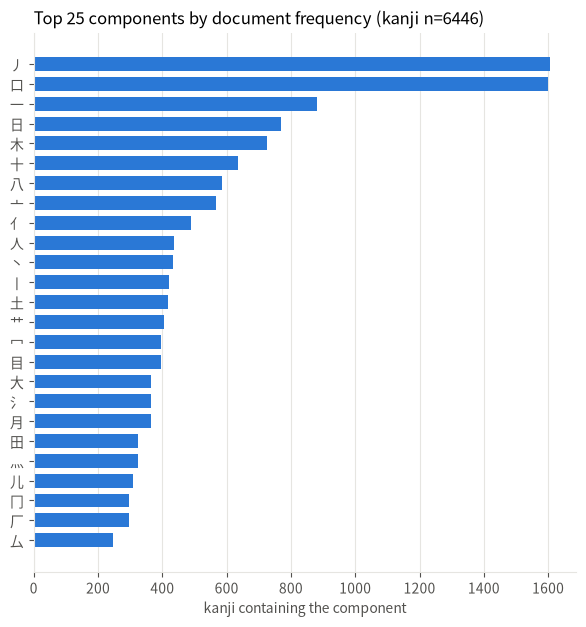

In [21]:
top_components = component_document_frequency.head(25).iloc[::-1]

figure, axis = plt.subplots(figsize=(7, 7))
axis.barh(top_components.index, top_components.values, color=SERIES_BLUE, height=0.7)
axis.set_xlabel("kanji containing the component")
axis.set_title(f"Top 25 components by document frequency (kanji n={len(kanji_table)})", loc="left")
axis.grid(True, axis="x")
axis.grid(False, axis="y")
plt.show()

In [22]:
frequency_buckets = pd.cut(
    component_document_frequency,
    bins=[0, 1, 2, 5, 10, 50, 100, 10_000],
    labels=["1", "2", "3-5", "6-10", "11-50", "51-100", ">100"],
)
bucket_counts = frequency_buckets.value_counts().sort_index()
bucket_share = (bucket_counts / len(component_document_frequency)).round(3)
pd.DataFrame({"elements": bucket_counts, "share": bucket_share})

,elements,share
character,,
1,376,0.257
2,188,0.128
3-5,299,0.204
6-10,235,0.161
11-50,235,0.161
51-100,61,0.042
>100,70,0.048


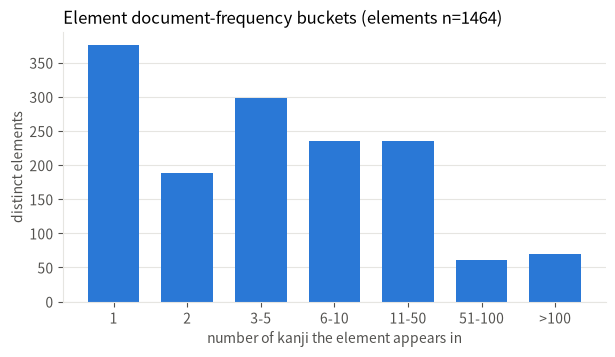

In [23]:
figure, axis = plt.subplots(figsize=(7, 3.5))
axis.bar(bucket_counts.index.astype(str), bucket_counts.values, color=SERIES_BLUE, width=0.7)
axis.set_xlabel("number of kanji the element appears in")
axis.set_ylabel("distinct elements")
axis.set_title(f"Element document-frequency buckets (elements n={len(component_document_frequency)})",
               loc="left")
plt.show()

In [24]:
cumulative_share = component_occurrences.cumsum() / component_occurrences.sum()
coverage_targets = [0.5, 0.8, 0.9, 0.95, 0.99]
elements_needed = {t: int((cumulative_share < t).sum() + 1) for t in coverage_targets}
pd.Series(elements_needed, name="elements needed").rename_axis("share of occurrences covered")

share of occurrences covered
0.50      37
0.80     171
0.90     382
0.95     628
0.99    1109
Name: elements needed, dtype: int64

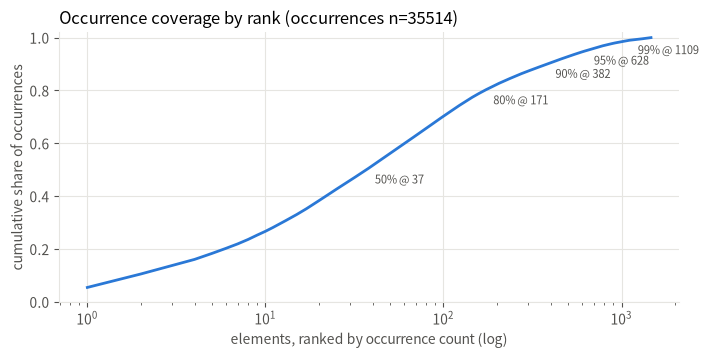

In [25]:
figure, axis = plt.subplots(figsize=(8, 3.5))
axis.plot(np.arange(1, len(cumulative_share) + 1), cumulative_share.values,
          color=SERIES_BLUE, linewidth=2)
axis.set_xscale("log")
axis.set_xlabel("elements, ranked by occurrence count (log)")
axis.set_ylabel("cumulative share of occurrences")
axis.set_title(f"Occurrence coverage by rank (occurrences n={component_occurrences.sum()})",
               loc="left")
axis.set_ylim(0, 1.02)
axis.grid(True, axis="both")
for target, rank in elements_needed.items():
    axis.annotate(f"{int(target * 100)}% @ {rank}", (rank, target), textcoords="offset points",
                  xytext=(6, -10), fontsize=8, color=TEXT_SECONDARY)
plt.show()

In [26]:
singleton_elements = component_document_frequency[component_document_frequency == 1]
kanji_with_singleton = first_parts[first_parts["element"].isin(singleton_elements.index)]["character"]
print("elements appearing in exactly 1 kanji:", len(singleton_elements),
      "of", len(component_document_frequency))
print("kanji containing at least one singleton element:", kanji_with_singleton.nunique(),
      "of", len(kanji_table))

elements appearing in exactly 1 kanji: 376 of 1464
kanji containing at least one singleton element: 364 of 6446


## 5. Structural annotations

In [27]:
annotation_columns = ["position", "radical", "variant", "original", "part", "partial", "phon"]
annotation_presence = component_groups[annotation_columns].notna().sum()
annotation_share = (annotation_presence / len(component_groups)).round(3)
pd.DataFrame({"groups with attribute": annotation_presence, "share of groups": annotation_share})

,groups with attribute,share of groups
position,26228,0.621
radical,7030,0.166
variant,5793,0.137
original,4346,0.103
part,3492,0.083
partial,474,0.011
phon,1364,0.032


In [28]:
position_counts = component_groups["position"].value_counts()
position_counts

position
bottom    6560
top       6551
right     5746
left      5739
tare       419
tarec      400
kamae      324
nyoc       221
nyo        221
kamaec      20
⿵A          11
⿵B           6
middle       5
⿶1           3
⿶2           2
Name: count, dtype: int64

⚠️ Position values with fewer than 50 groups are folded into `other` in the chart only.

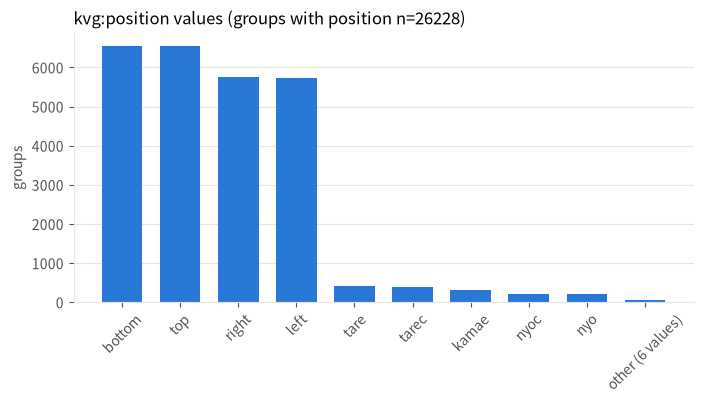

In [29]:
rare_position_mask = position_counts < 50
plotted_position_counts = position_counts[~rare_position_mask].copy()
plotted_position_counts[f"other ({rare_position_mask.sum()} values)"] = position_counts[rare_position_mask].sum()

figure, axis = plt.subplots(figsize=(8, 3.5))
axis.bar(plotted_position_counts.index, plotted_position_counts.values, color=SERIES_BLUE, width=0.7)
axis.set_ylabel("groups")
axis.set_title(f"kvg:position values (groups with position n={position_counts.sum()})", loc="left")
axis.tick_params(axis="x", rotation=45)
plt.show()

In [30]:
radical_counts = component_groups["radical"].value_counts()
kanji_with_radical = component_groups[component_groups["radical"].notna()]["character"].nunique()
print("kanji with at least one radical-marked group:", kanji_with_radical, "of", len(character_table))
radical_counts

kanji with at least one radical-marked group: 6190 of 6703


radical
general    5586
tradit      765
nelson      676
jis           3
Name: count, dtype: int64

In [31]:
variant_groups = component_groups[component_groups["variant"].notna()]
print("variant groups:", len(variant_groups), " distinct elements:", variant_groups["element"].nunique())
variant_groups["element"].value_counts().head(10)

variant groups: 5793  distinct elements: 323


element
亻    498
艹    395
氵    361
灬    324
扌    226
𠂊    190
月    159
八    139
⺕    132
忄    131
Name: count, dtype: int64

In [32]:
original_groups = component_groups[component_groups["original"].notna()]
print("groups with kvg:original:", len(original_groups))
original_groups[["element", "original"]].value_counts().head(10)

groups with kvg:original: 4346


element  original
亻        人           504
艹        艸           403
氵        水           365
灬        火           327
扌        手           230
儿        八           224
𠂊        勹           192
王        玉           146
月        肉           134
⺕        彑           133
Name: count, dtype: int64

## 6. Stroke types

In [33]:
print("strokes:", len(stroke_table))
print("strokes without kvg:type:", stroke_table["stroke_type"].isna().sum())
print("distinct stroke types:", stroke_table["stroke_type"].nunique())

strokes: 79921
strokes without kvg:type: 670
distinct stroke types: 91


In [34]:
stroke_table["base_stroke_type"] = stroke_table["stroke_type"].str[:1]
base_stroke_type_counts = stroke_table["base_stroke_type"].value_counts()
print("distinct base stroke types (suffix letters stripped):", len(base_stroke_type_counts))
base_stroke_type_counts.head(20)

distinct base stroke types (suffix letters stripped): 29


base_stroke_type
㇐    23011
㇑    15682
㇒    12170
㇔     9719
㇕     5268
㇏     2684
㇀     1838
㇆     1797
㇇     1104
㇟      910
㇜      895
㇚      854
㇖      697
㇄      346
㇁      343
㇛      314
㇙      307
㇂      229
㇓      194
㇈      192
Name: count, dtype: int64

⚠️ Base stroke type = first character of `kvg:type`; suffixes like `a`/`b`/`c` are treated as
sub-variants of the same stroke. This merges e.g. `㇐`, `㇐a`, `㇐b`.

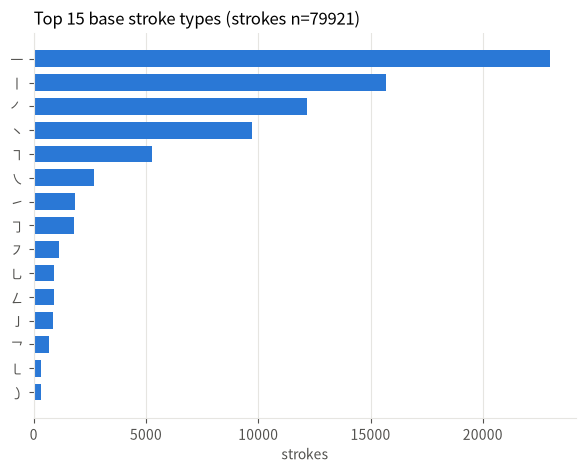

In [35]:
top_base_strokes = base_stroke_type_counts.head(15).iloc[::-1]

figure, axis = plt.subplots(figsize=(7, 5))
axis.barh(top_base_strokes.index, top_base_strokes.values, color=SERIES_BLUE, height=0.7)
axis.set_xlabel("strokes")
axis.set_title(f"Top 15 base stroke types (strokes n={len(stroke_table)})", loc="left")
axis.grid(True, axis="x")
axis.grid(False, axis="y")
plt.show()

## 7. Sample characters

明 components: ['日', '月']


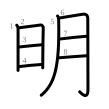

顔 components: ['彦', '立', '厂', '厂', '彡', '頁', '貝', '目']


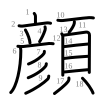

丗 components: ['卅', '廾', '廿', '一', '川', '丿', '廿', '丨', '廿', '川', '廿']


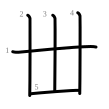

あ components: (not CJK)


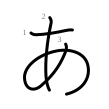

In [36]:
sample_characters = ["明", "顔", "丗", "あ"]
for character in sample_characters:
    filepath = KANJIVG_DIR / f"{ord(character):05x}.svg"
    print(character, "components:",
          kanji_components[kanji_components["character"] == character]["element"].tolist()
          if character in set(kanji_table["character"]) else "(not CJK)")
    display(SVG(filename=str(filepath)))